<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HECKTORLR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 3.16MB/s]



DATA SUMMARY
Rows: 588
Class distribution: {0: 58, 1: 530}
Number of predictors: 8
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

================== FOLD 1/3 ==================



VALIDATION METRICS
 fold                 1.000000
Accuracy             0.852041
Balanced_Accuracy    0.730152
Precision            0.951220
Recall               0.881356
F1                   0.914956
ROC_AUC              0.779215
PR_AUC               0.968362
Threshold            0.315000
dtype: float64

CONFUSION MATRIX
 [[ 11   8]
 [ 21 156]]

CLASSIFICATION REPORT
               precision    recall  f1-score   support

           0       0.34      0.58      0.43        19
           1       0.95      0.88      0.91       177

    accuracy                           0.85       196
   macro avg       0.65      0.73      0.67       196
weighted avg       0.89      0.85      0.87       196


================== FOLD 2/3 ==================



VALIDATION METRICS
 fold                 2.000000
Accuracy             0.755102
Balanced_Accuracy    0.793934
Precision            0.977778
Recall               0.745763
F1                   0.846154
ROC_AUC              0.818168
PR_AUC               0.973788
Threshold            0.540000
dtype: float64

CONFUSION MATRIX
 [[ 16   3]
 [ 45 132]]

CLASSIFICATION REPORT
               precision    recall  f1-score   support

           0       0.26      0.84      0.40        19
           1       0.98      0.75      0.85       177

    accuracy                           0.76       196
   macro avg       0.62      0.79      0.62       196
weighted avg       0.91      0.76      0.80       196


================== FOLD 3/3 ==================



VALIDATION METRICS
 fold                 3.000000
Accuracy             0.790816
Balanced_Accuracy    0.817045
Precision            0.978723
Recall               0.784091
F1                   0.870662
ROC_AUC              0.872017
PR_AUC               0.983712
Threshold            0.490000
dtype: float64

CONFUSION MATRIX
 [[ 17   3]
 [ 38 138]]

CLASSIFICATION REPORT
               precision    recall  f1-score   support

           0       0.31      0.85      0.45        20
           1       0.98      0.78      0.87       176

    accuracy                           0.79       196
   macro avg       0.64      0.82      0.66       196
weighted avg       0.91      0.79      0.83       196


THREE-FOLD METRICS (MEAN ± SD)
                        mean       std
Accuracy           0.799320  0.049026
Balanced_Accuracy  0.780377  0.045005
Precision          0.969240  0.015614
Recall             0.803737  0.069899
F1                 0.877257  0.034872
ROC_AUC            0.823133  0.046600
PR

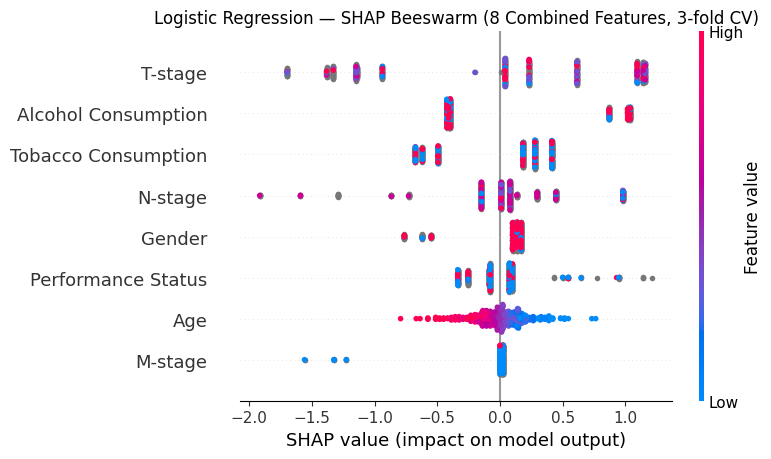

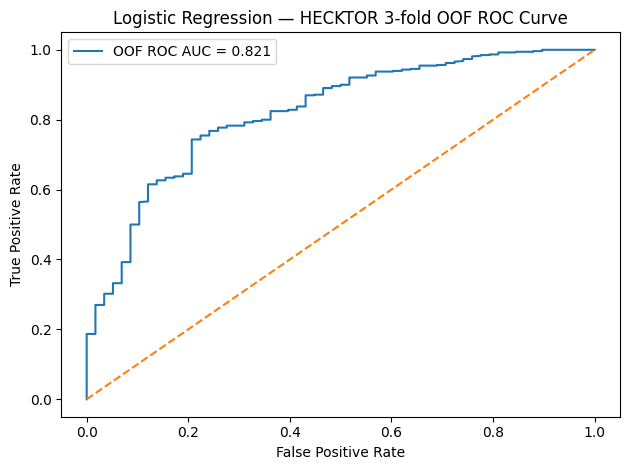

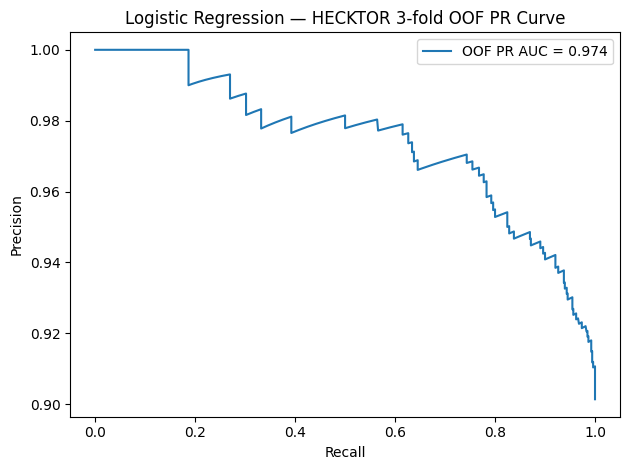


All outputs saved to: /content/drive/MyDrive/LR_results_HECKTOR_3fold
Files include fold metrics, mean±SD metrics, OOF predictions,
mean±SD SHAP/LIME, combined-feature SHAP beeswarm and ROC/PR curves.


In [2]:
# ============================================================
# LOGISTIC REGRESSION — HECKTOR HPV CLASSIFIER
# Stratified 3-fold CV | Seed 42 | No test set | No SMOTE
# ============================================================

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown
!pip install -q lime shap gdown
import shap
from lime.lime_tabular import LimeTabularExplainer

from google.colab import drive
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
drive.mount("/content/drive")

# 1. LOAD AND PREPARE DATA
gdown.download(
    id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
    output="HPV2025.xlsx",
    quiet=False
)
BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "LR_results_HECKTOR_3fold")
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_excel("HPV2025.xlsx")
df = df.dropna(subset=["HPV Status"]).copy()
if "PatientID" in df.columns:
    df = df.rename(columns={"PatientID": "patient_id"})
elif "patient_id" not in df.columns:
    df["patient_id"] = np.arange(len(df))
df["HPV_Label"] = pd.to_numeric(df["HPV Status"], errors="coerce")
df = df.dropna(subset=["HPV_Label"]).copy()
df = df[df["HPV_Label"].isin([0, 1])].copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

# Exactly eight predictors; Relapse, RFS and Treatment are excluded
features = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(
        f"Missing predictor columns: {missing_features}\n"
        f"Available columns: {df.columns.tolist()}"
    )
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df[["patient_id"] + features + ["HPV_Label"]].copy()
print("\nDATA SUMMARY")
print("Rows:", len(df))
print("Class distribution:", df["HPV_Label"].value_counts().sort_index().to_dict())
print("Number of predictors:", len(features))
print("Predictors:", features)
if df["HPV_Label"].nunique() != 2:
    raise ValueError("HPV_Label must contain both classes 0 and 1.")
if df["HPV_Label"].value_counts().min() < 3:
    raise ValueError("Too few samples in one class for 3-fold stratification.")

# 2. THREE-FOLD CROSS-VALIDATION
numeric_features = ["Age"]
categorical_features = [c for c in features if c not in numeric_features]
thresholds = np.linspace(0.10, 0.90, 161)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_metrics, oof_rows = [], []
fold_shap_values, fold_shap_data = [], []
fold_lime_importance, fold_models, fold_preprocessors = [], [], []
category_maps = {
    feature: {
        value: index for index, value in enumerate(
            sorted(df[feature].dropna().astype(str).unique())
        )
    }
    for feature in categorical_features
}

for fold, (train_idx, val_idx) in enumerate(
    cv.split(df[features], df["HPV_Label"]), start=1
):
    print(f"\n{'=' * 18} FOLD {fold}/3 {'=' * 18}")
    train = df.iloc[train_idx].copy()
    val = df.iloc[val_idx].copy()
    y_train = train["HPV_Label"].to_numpy()
    y_val = val["HPV_Label"].to_numpy()

    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", encoder)
        ]), categorical_features)
    ])
    X_train = preprocessor.fit_transform(train[features])
    X_val = preprocessor.transform(val[features])
    feature_names = preprocessor.get_feature_names_out()

    model = LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=SEED
    )
    model.fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    threshold_scores = [
        balanced_accuracy_score(y_val, (val_prob >= threshold).astype(int))
        for threshold in thresholds
    ]
    best_score = max(threshold_scores)
    best_threshold = min(
        (threshold for threshold, score in zip(thresholds, threshold_scores)
         if np.isclose(score, best_score)),
        key=lambda threshold: abs(threshold - 0.5)
    )
    val_pred = (val_prob >= best_threshold).astype(int)
    metrics = {
        "fold": fold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y_val, val_prob)
            if len(np.unique(y_val)) == 2 else np.nan
        ),
        "PR_AUC": average_precision_score(y_val, val_prob),
        "Threshold": float(best_threshold)
    }
    fold_metrics.append(metrics)
    print("\nVALIDATION METRICS\n", pd.Series(metrics))
    print("\nCONFUSION MATRIX\n", confusion_matrix(y_val, val_pred))
    print("\nCLASSIFICATION REPORT\n",
          classification_report(y_val, val_pred, zero_division=0))
    oof_rows.append(pd.DataFrame({
        "fold": fold, "patient_id": val["patient_id"].to_numpy(),
        "y_true": y_val, "probability_positive": val_prob,
        "prediction": val_pred
    }))

    # Save each fold's fitted model and preprocessing pipeline
    import joblib
    joblib.dump(model, os.path.join(OUT_DIR, f"fold_{fold}_model.joblib"))
    joblib.dump(
        preprocessor, os.path.join(OUT_DIR, f"fold_{fold}_preprocessor.joblib")
    )
    fold_models.append(model)
    fold_preprocessors.append(preprocessor)

    # SHAP: sum one-hot contributions into the eight original predictors
    explainer = shap.LinearExplainer(model, X_train)
    shap_raw = explainer.shap_values(X_val)
    shap_matrix = np.asarray(shap_raw)
    if shap_matrix.ndim == 3:
        shap_matrix = shap_matrix[:, :, -1]
    if shap_matrix.ndim == 1:
        shap_matrix = shap_matrix.reshape(1, -1)
    grouped_shap = np.zeros((len(X_val), len(features)))
    grouped_data = pd.DataFrame(index=range(len(X_val)))
    for feature_idx, feature in enumerate(features):
        cols = [
            i for i, name in enumerate(feature_names)
            if name == f"num__{feature}" or name.startswith(f"cat__{feature}_")
        ]
        if cols:
            grouped_shap[:, feature_idx] = shap_matrix[:, cols].sum(axis=1)
        if feature in numeric_features:
            grouped_data[feature] = X_val[:, cols[0]] if cols else 0.0
        else:
            mode = train[feature].mode(dropna=True)
            fill_value = mode.iloc[0] if len(mode) else ""
            values = val[feature].fillna(fill_value).astype(str)
            grouped_data[feature] = (
                values.map(category_maps[feature]).fillna(-1)
            )
    fold_shap_values.append(grouped_shap)
    fold_shap_data.append(grouped_data[features])

    # LIME: mean absolute contribution, grouped by original predictor
    lime_explainer = LimeTabularExplainer(
        X_train, feature_names=list(feature_names),
        class_names=["HPV-negative", "HPV-positive"],
        mode="classification", discretize_continuous=True,
        random_state=SEED + fold
    )
    sample_n = min(50, len(X_val))
    sample_idx = np.linspace(0, len(X_val) - 1, sample_n, dtype=int)
    lime_scores = {feature: [] for feature in features}
    for row_idx in sample_idx:
        explanation = lime_explainer.explain_instance(
            X_val[row_idx], model.predict_proba,
            num_features=len(feature_names), labels=(1,)
        )
        for encoded_name, weight in explanation.as_list(label=1):
            matched = next(
                (feature for feature in features
                 if encoded_name.startswith(f"num__{feature}")
                 or encoded_name.startswith(f"cat__{feature}_")),
                None
            )
            if matched is not None:
                lime_scores[matched].append(abs(float(weight)))
    fold_lime_importance.append({
        feature: float(np.mean(values)) if values else 0.0
        for feature, values in lime_scores.items()
    })

# 3. THREE-FOLD RESULTS: MEAN AND STANDARD DEVIATION
metrics_df = pd.DataFrame(fold_metrics)
metrics_df.to_csv(os.path.join(OUT_DIR, "fold_metrics.csv"), index=False)
summary = metrics_df.drop(columns=["fold"]).agg(["mean", "std"]).T
summary.to_csv(os.path.join(OUT_DIR, "metrics_mean_sd.csv"))
print("\nTHREE-FOLD METRICS (MEAN ± SD)\n", summary)
oof = pd.concat(oof_rows, ignore_index=True)
oof.to_csv(os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)
pd.DataFrame(fold_lime_importance).agg(["mean", "std"]).T.to_csv(
    os.path.join(OUT_DIR, "lime_importance_mean_sd.csv")
)

# Mean absolute SHAP across folds, with encoded columns combined by feature
shap_fold_means = [
    dict(zip(features, np.abs(values).mean(axis=0)))
    for values in fold_shap_values
]
pd.DataFrame(shap_fold_means).agg(["mean", "std"]).T.to_csv(
    os.path.join(OUT_DIR, "shap_importance_mean_sd.csv")
)

# SHAP beeswarm: exactly eight rows, one per original predictor
all_shap = np.vstack(fold_shap_values)
all_shap_data = pd.concat(fold_shap_data, ignore_index=True)[features]
shap.summary_plot(
    all_shap, all_shap_data, feature_names=features,
    plot_type="dot", show=False, max_display=len(features)
)
plt.title("Logistic Regression — SHAP Beeswarm (8 Combined Features, 3-fold CV)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "shap_beeswarm.png"), dpi=180)
plt.show()

# ROC and precision-recall curves from pooled out-of-fold predictions
y_true = oof["y_true"].to_numpy()
oof_prob = oof["probability_positive"].to_numpy()
if len(np.unique(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, oof_prob)
    auc = roc_auc_score(y_true, oof_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"OOF ROC AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Logistic Regression — HECKTOR 3-fold OOF ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve_oof.png"), dpi=150)
    plt.show()
precision, recall, _ = precision_recall_curve(y_true, oof_prob)
pr_auc = average_precision_score(y_true, oof_prob)
plt.figure()
plt.plot(recall, precision, label=f"OOF PR AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression — HECKTOR 3-fold OOF PR Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "pr_curve_oof.png"), dpi=150)
plt.show()

settings = {
    "model": "Logistic Regression", "dataset": "HECKTOR", "seed": SEED,
    "features": features, "excluded_features": ["Relapse", "RFS", "Treatment"],
    "target_column": "HPV Status", "folds": 3, "test_set": False,
    "threshold_selection": "Validation balanced accuracy within each fold",
    "thresholds": [float(x) for x in thresholds],
    "class_weight": "balanced", "smote": False,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "shap_beeswarm_features": "eight original predictors; one row per predictor"
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)
print("\nAll outputs saved to:", OUT_DIR)
print("Files include fold metrics, mean±SD metrics, OOF predictions,")
print("mean±SD SHAP/LIME, combined-feature SHAP beeswarm and ROC/PR curves.")
